<a href="https://colab.research.google.com/github/devcodes28/AI-ML-Lab-24CSP503/blob/main/logistic_regression_titanic.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Logistic Regression on the Titanic Dataset
**Goal:** predict whether a passenger survived (`Survived` = 1) or not (`Survived` = 0).

**Dataset:** Kaggle's *Titanic - Machine Learning from Disaster* (`train.csv`).

**Workflow**
1. Load data
2. Exploratory data analysis (EDA)
3. Preprocessing (missing values, feature engineering, encoding, scaling)
4. Train / test split
5. Train Logistic Regression
6. Evaluate (accuracy, confusion matrix, ROC, precision-recall)
7. Interpret coefficients
8. Cross-validation and hyper-parameter tuning

## 1. Imports and settings

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             roc_curve, roc_auc_score, precision_recall_curve)

import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (7, 4.5)
RANDOM_STATE = 42  # for reproducibility

## 2. Load the data
The CSV below is a public mirror of Kaggle's Titanic `train.csv`.
If you downloaded it from Kaggle, replace the URL with the local path, e.g. `"train.csv"`.

In [ ]:
URL = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df = pd.read_csv(URL)   # or: pd.read_csv("train.csv")
print("Shape:", df.shape)
df.head()

Shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


**Column meanings**

| Column | Meaning |
|---|---|
| Survived | Target: 0 = died, 1 = survived |
| Pclass | Ticket class (1 = upper, 3 = lower) |
| Name, Sex, Age | Passenger details |
| SibSp / Parch | Siblings-spouses / parents-children aboard |
| Ticket, Fare, Cabin | Ticket number, fare paid, cabin |
| Embarked | Port: C = Cherbourg, Q = Queenstown, S = Southampton |

## 3. Exploratory data analysis

In [ ]:
df.info()
print()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB



,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


### 3.1 Missing values

Cabin       687
Age         177
Embarked      2
dtype: int64


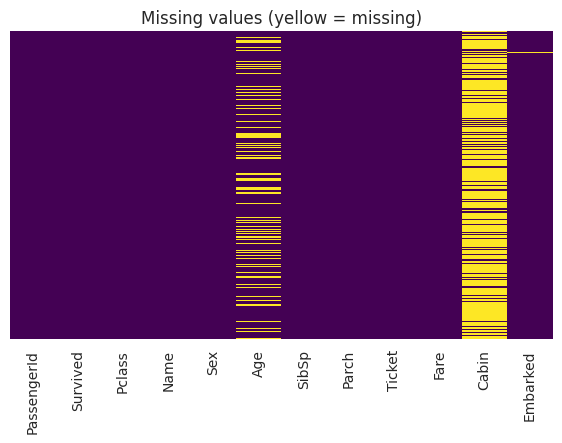

In [ ]:
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print(missing)

plt.figure(figsize=(7, 4))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap="viridis")
plt.title("Missing values (yellow = missing)")
plt.show()

`Cabin` is mostly missing (~77%), `Age` is missing ~20%, `Embarked` only 2 rows. We'll handle each differently below.

### 3.2 Target distribution (class balance)

Survived
0    0.616
1    0.384
Name: proportion, dtype: float64


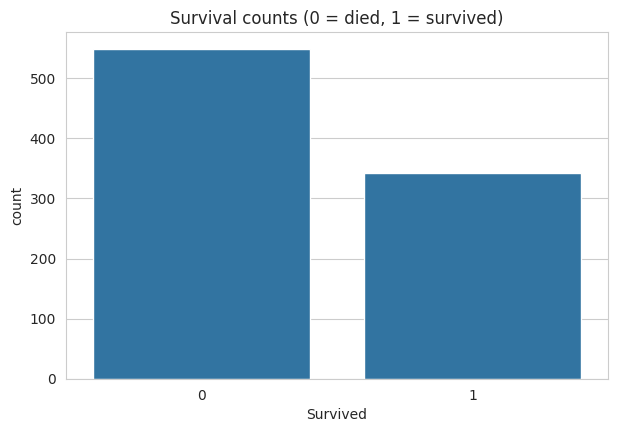

In [ ]:
print(df["Survived"].value_counts(normalize=True).round(3))
sns.countplot(x="Survived", data=df)
plt.title("Survival counts (0 = died, 1 = survived)")
plt.show()

The classes are moderately imbalanced (~62% died / 38% survived), which is fine for logistic regression, but we'll use a *stratified* split to preserve the ratio.

### 3.3 Survival vs. key features

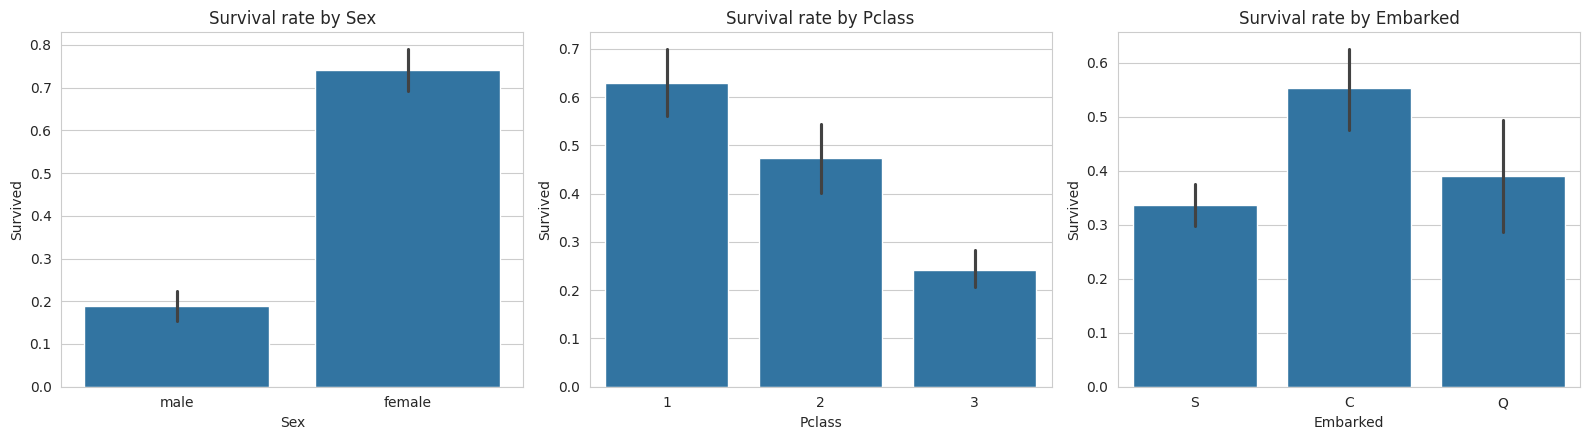

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sns.barplot(x="Sex", y="Survived", data=df, ax=axes[0])
axes[0].set_title("Survival rate by Sex")
sns.barplot(x="Pclass", y="Survived", data=df, ax=axes[1])
axes[1].set_title("Survival rate by Pclass")
sns.barplot(x="Embarked", y="Survived", data=df, ax=axes[2])
axes[2].set_title("Survival rate by Embarked")
plt.tight_layout()
plt.show()

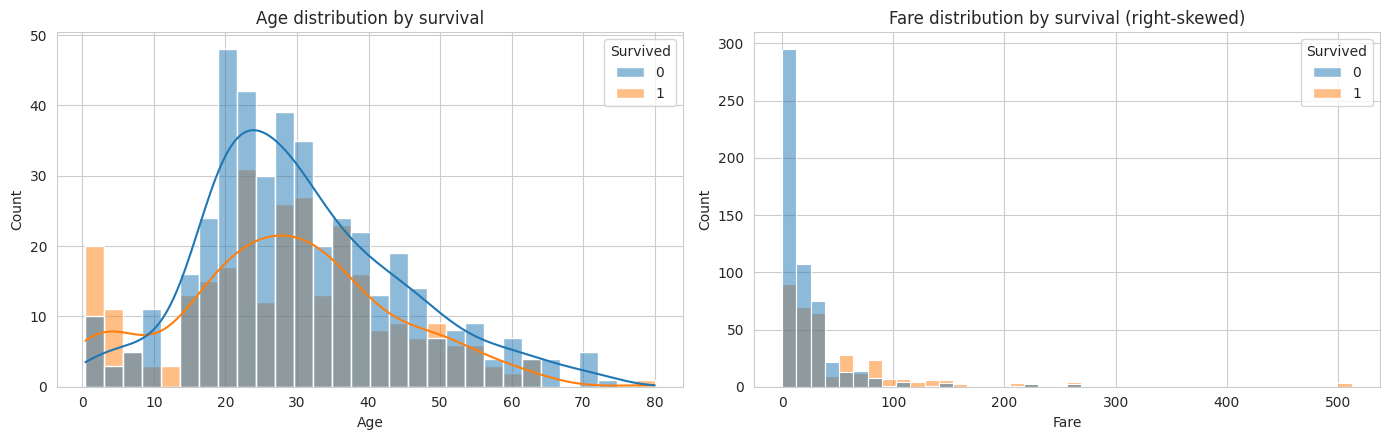

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(data=df, x="Age", hue="Survived", bins=30, kde=True, ax=axes[0])
axes[0].set_title("Age distribution by survival")
sns.histplot(data=df, x="Fare", hue="Survived", bins=40, ax=axes[1])
axes[1].set_title("Fare distribution by survival (right-skewed)")
plt.tight_layout()
plt.show()

## 4. Preprocessing & feature engineering

Steps:
1. **Drop** useless columns (`PassengerId`, `Ticket`, `Cabin` - too many missing / unique values).
2. **Extract `Title`** from `Name` (Mr, Mrs, Miss...), which is a strong signal and helps impute age.
3. **Create `FamilySize`** and `IsAlone`.
4. **Impute** missing `Age` (median by Title), `Embarked` (mode), `Fare` (median).
5. **Log-transform `Fare`** to reduce skew.
6. **One-hot encode** categorical variables.
7. **Scale** numeric variables (logistic regression with regularisation is scale sensitive).

In [ ]:
data = df.copy()

# 1. Feature engineering: Title from Name ("Braund, Mr. Owen Harris" -> "Mr")
data["Title"] = data["Name"].str.extract(r",\s*([^\.]+)\.", expand=False).str.strip()

# Group rare titles together
title_map = {"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"}
data["Title"] = data["Title"].replace(title_map)
common = ["Mr", "Mrs", "Miss", "Master"]
data["Title"] = data["Title"].where(data["Title"].isin(common), "Rare")
print(data["Title"].value_counts())

# 2. Family features
data["FamilySize"] = data["SibSp"] + data["Parch"] + 1
data["IsAlone"] = (data["FamilySize"] == 1).astype(int)

# 3. Drop columns we won't use
data = data.drop(columns=["PassengerId", "Name", "Ticket", "Cabin"])

Title
Mr        517
Miss      185
Mrs       126
Master     40
Rare       23
Name: count, dtype: int64


In [ ]:
# 4. Handle missing values
# Age: fill with the median age of the passenger's Title (e.g. 'Master' = young boys)
data["Age"] = data["Age"].fillna(data.groupby("Title")["Age"].transform("median"))
# Embarked: fill with most frequent port
data["Embarked"] = data["Embarked"].fillna(data["Embarked"].mode()[0])
# Fare: fill with median (safe even if no NaN)
data["Fare"] = data["Fare"].fillna(data["Fare"].median())

print("Remaining missing values:", data.isnull().sum().sum())

Remaining missing values: 0


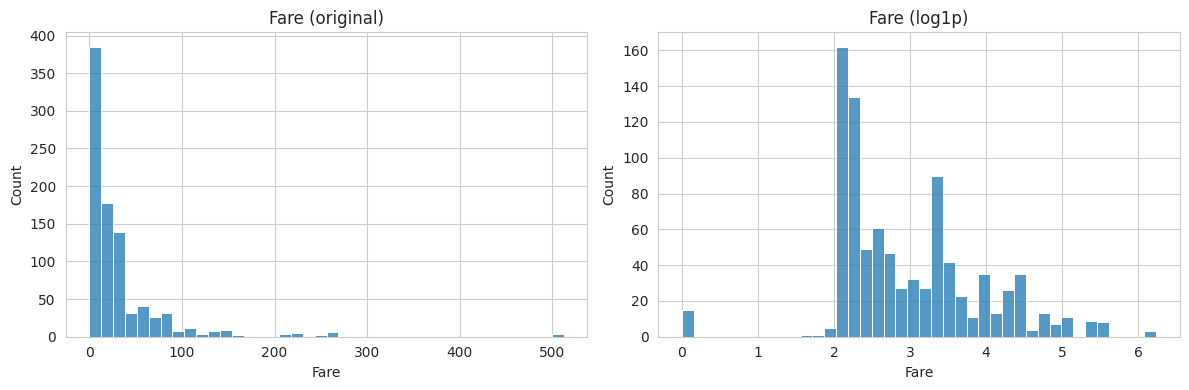

In [ ]:
# 5. Outliers / skew: log transform Fare
data["Fare"] = np.log1p(data["Fare"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["Fare"], bins=40, ax=axes[0]); axes[0].set_title("Fare (original)")
sns.histplot(data["Fare"], bins=40, ax=axes[1]); axes[1].set_title("Fare (log1p)")
plt.tight_layout(); plt.show()

In [ ]:
# 6. One-hot encode categorical columns (drop_first avoids the dummy-variable trap)
data = pd.get_dummies(data, columns=["Sex", "Embarked", "Title", "Pclass"], drop_first=True, dtype=int)
data.head()

,Survived,Age,SibSp,Parch,Fare,FamilySize,IsAlone,Sex_male,Embarked_Q,Embarked_S,Title_Miss,Title_Mr,Title_Mrs,Title_Rare,Pclass_2,Pclass_3
0,0,22.0,1,0,2.110213,2,0,1,0,1,0,1,0,0,0,1
1,1,38.0,1,0,4.280593,2,0,0,0,0,0,0,1,0,0,0
2,1,26.0,0,0,2.188856,1,1,0,0,1,1,0,0,0,0,1
3,1,35.0,1,0,3.990834,2,0,0,0,1,0,0,1,0,0,0
4,0,35.0,0,0,2.202765,1,1,1,0,1,0,1,0,0,0,1


### Correlation heatmap

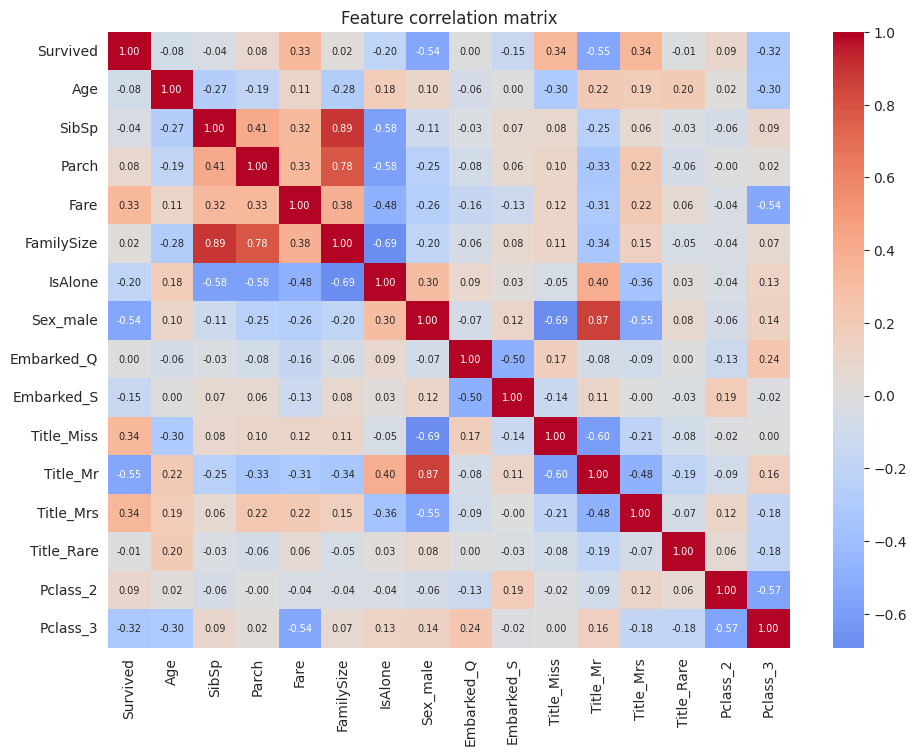

In [ ]:
plt.figure(figsize=(11, 8))
sns.heatmap(data.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 7})
plt.title("Feature correlation matrix")
plt.show()

`Sex_male` and `Title_Mr` are strongly (negatively) correlated with survival. `FamilySize` and `IsAlone` overlap, but logistic regression with regularisation handles mild multicollinearity fine.

## 5. Train / test split and scaling

In [ ]:
X = data.drop(columns="Survived")
y = data["Survived"]

# Stratify keeps the survived/died ratio equal in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Train survival rate:", round(y_train.mean(), 3), "| Test survival rate:", round(y_test.mean(), 3))

# Scale numeric columns. Fit ONLY on training data to avoid data leakage.
num_cols = ["Age", "Fare", "SibSp", "Parch", "FamilySize"]
scaler = StandardScaler()
X_train = X_train.copy(); X_test = X_test.copy()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

Train: (712, 15)  Test: (179, 15)
Train survival rate: 0.383 | Test survival rate: 0.385


## 6. Train Logistic Regression

Logistic regression models the probability of survival as:

$$P(y=1 \mid x) = \frac{1}{1 + e^{-(\beta_0 + \beta_1 x_1 + \dots + \beta_n x_n)}}$$

A passenger is predicted as 'survived' if this probability is >= 0.5.

In [ ]:
model = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]   # probability of survival

## 7. Evaluation

In [ ]:
print(f"Train accuracy: {model.score(X_train, y_train):.3f}")
print(f"Test accuracy : {accuracy_score(y_test, y_pred):.3f}")
print(f"Precision     : {precision_score(y_test, y_pred):.3f}")
print(f"Recall        : {recall_score(y_test, y_pred):.3f}")
print(f"F1-score      : {f1_score(y_test, y_pred):.3f}")
print(f"ROC-AUC       : {roc_auc_score(y_test, y_prob):.3f}")
print()
print(classification_report(y_test, y_pred, target_names=["Died", "Survived"]))

Train accuracy: 0.829
Test accuracy : 0.827
Precision     : 0.797
Recall        : 0.739
F1-score      : 0.767
ROC-AUC       : 0.869

              precision    recall  f1-score   support

        Died       0.84      0.88      0.86       110
    Survived       0.80      0.74      0.77        69

    accuracy                           0.83       179
   macro avg       0.82      0.81      0.81       179
weighted avg       0.83      0.83      0.83       179



Similar train and test accuracy means the model is **not overfitting**.

### 7.1 Confusion matrix

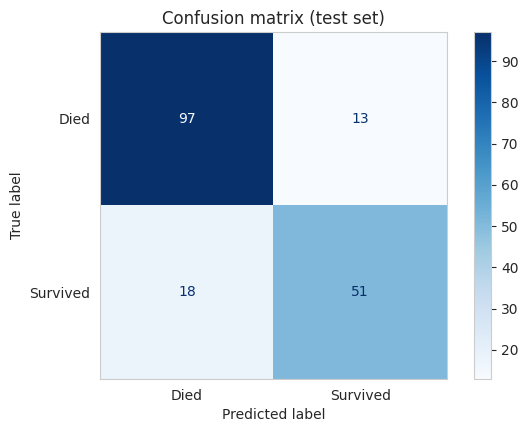

In [ ]:
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["Died", "Survived"]).plot(cmap="Blues", values_format="d")
plt.title("Confusion matrix (test set)")
plt.grid(False)
plt.show()

### 7.2 ROC curve and Precision-Recall curve

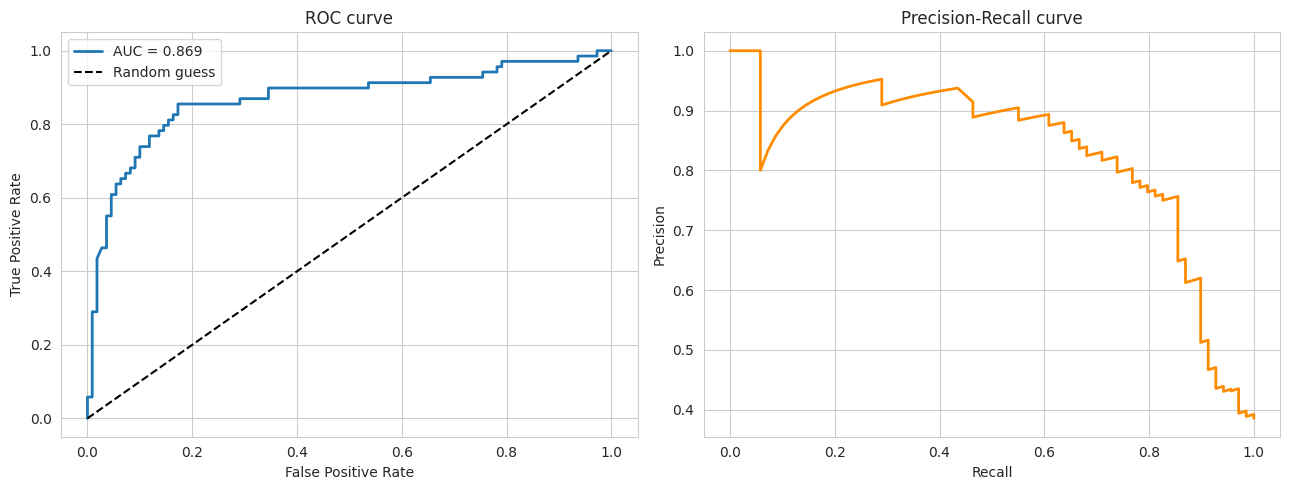

In [ ]:
fpr, tpr, _ = roc_curve(y_test, y_prob)
prec, rec, _ = precision_recall_curve(y_test, y_prob)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_test, y_prob):.3f}", lw=2)
axes[0].plot([0, 1], [0, 1], "k--", label="Random guess")
axes[0].set_xlabel("False Positive Rate"); axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("ROC curve"); axes[0].legend()

axes[1].plot(rec, prec, lw=2, color="darkorange")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall curve")
plt.tight_layout(); plt.show()

### 7.3 Distribution of predicted probabilities

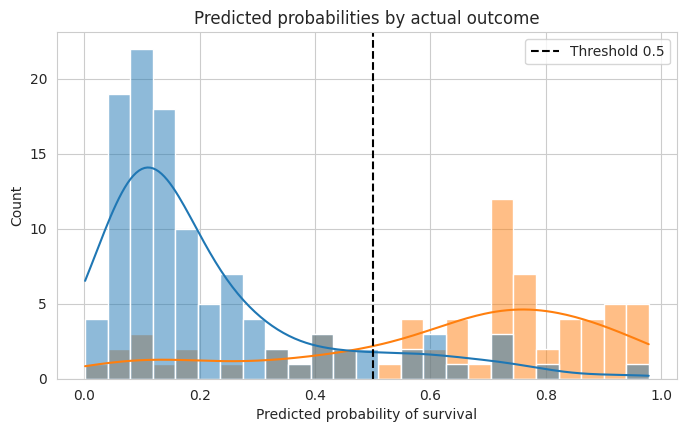

In [ ]:
plt.figure(figsize=(8, 4.5))
sns.histplot(x=y_prob, hue=y_test.map({0: "Died", 1: "Survived"}), bins=25, kde=True)
plt.axvline(0.5, color="k", linestyle="--", label="Threshold 0.5")
plt.xlabel("Predicted probability of survival")
plt.title("Predicted probabilities by actual outcome")
plt.legend(); plt.show()

## 8. Interpreting the model (coefficients)

Each coefficient is the change in **log-odds** of survival for a one-unit increase in that feature.
`exp(coef)` gives the **odds ratio**: >1 raises survival odds, <1 lowers them.

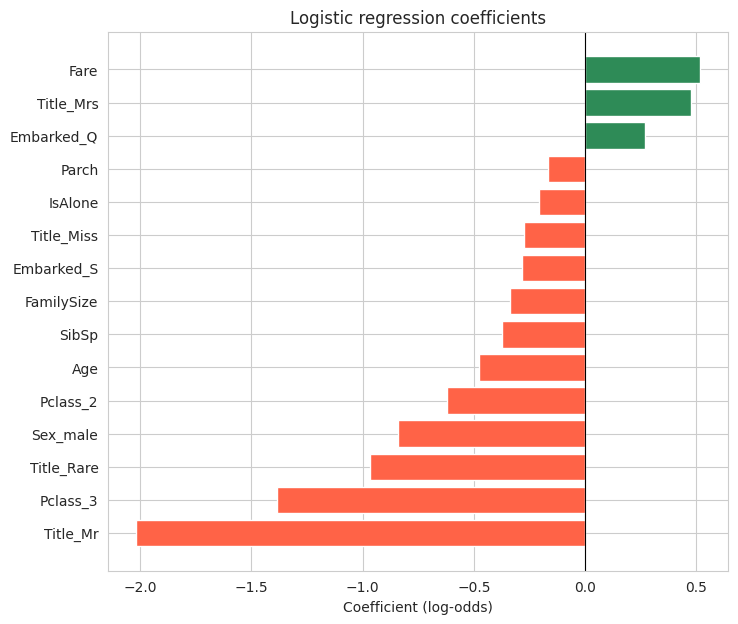

,Feature,Coefficient,Odds_Ratio
0,Fare,0.516116,1.675508
1,Title_Mrs,0.477873,1.612640
2,Embarked_Q,0.269650,1.309506
3,Parch,-0.165163,0.847756
4,IsAlone,-0.207756,0.812405
5,Title_Miss,-0.272530,0.761451
6,Embarked_S,-0.284137,0.752664
7,FamilySize,-0.337519,0.713538
8,SibSp,-0.375128,0.687201
9,Age,-0.474512,0.622188


In [ ]:
coef_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": model.coef_[0],
    "Odds_Ratio": np.exp(model.coef_[0])
}).sort_values("Coefficient")

plt.figure(figsize=(8, 7))
colors = ["tomato" if c < 0 else "seagreen" for c in coef_df["Coefficient"]]
plt.barh(coef_df["Feature"], coef_df["Coefficient"], color=colors)
plt.axvline(0, color="k", lw=0.8)
plt.title("Logistic regression coefficients")
plt.xlabel("Coefficient (log-odds)")
plt.show()

coef_df.sort_values("Coefficient", ascending=False).reset_index(drop=True)

Being male, in 3rd class, or having a large family lowers survival odds, while being a young child ('Master') or a woman ('Mrs'/'Miss') raises them, which matches the 'women and children first' history.

## 9. Cross-validation

In [ ]:
# 5-fold stratified CV on the full dataset gives a more robust estimate than one split.
# A scaler inside a Pipeline avoids leakage across folds.
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

X_all = data.drop(columns="Survived")
y_all = data["Survived"]

prep = ColumnTransformer([("num", StandardScaler(), num_cols)], remainder="passthrough")
pipe = Pipeline([("prep", prep), ("clf", LogisticRegression(max_iter=1000))])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scores = cross_val_score(pipe, X_all, y_all, cv=cv, scoring="accuracy")
print("Fold accuracies:", scores.round(3))
print(f"Mean CV accuracy: {scores.mean():.3f} (+/- {scores.std():.3f})")

Fold accuracies: [0.827 0.815 0.826 0.831 0.826]
Mean CV accuracy: 0.825 (+/- 0.006)


## 10. Hyper-parameter tuning

`C` is the inverse of regularisation strength (smaller = stronger regularisation).
We tune `C` and the penalty type with grid search.

In [ ]:
param_grid = {
    "clf__C": [0.01, 0.1, 1, 10, 100],
    "clf__penalty": ["l1", "l2"],
    "clf__solver": ["liblinear"],   # supports both l1 and l2
}
grid = GridSearchCV(pipe, param_grid, cv=cv, scoring="accuracy", n_jobs=-1)
grid.fit(X_all, y_all)

print("Best params :", grid.best_params_)
print(f"Best CV accuracy: {grid.best_score_:.3f}")

Best params : {'clf__C': 10, 'clf__penalty': 'l2', 'clf__solver': 'liblinear'}
Best CV accuracy: 0.827


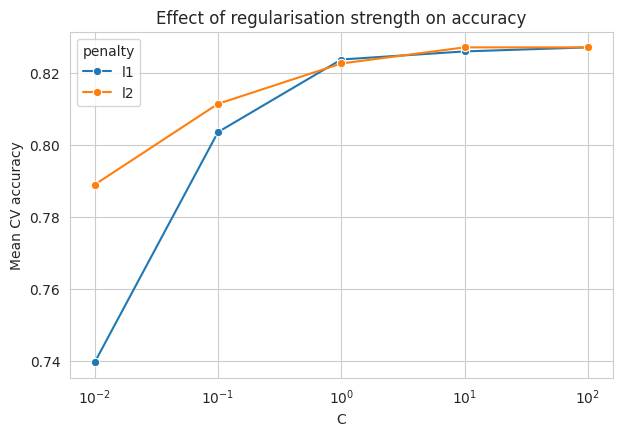

In [ ]:
# Visualise how C affects accuracy
res = pd.DataFrame(grid.cv_results_)
res["C"] = res["param_clf__C"].astype(float)
res["penalty"] = res["param_clf__penalty"]

plt.figure(figsize=(7, 4.5))
sns.lineplot(data=res, x="C", y="mean_test_score", hue="penalty", marker="o")
plt.xscale("log")
plt.ylabel("Mean CV accuracy")
plt.title("Effect of regularisation strength on accuracy")
plt.show()

## 11. Final model check on the held-out test set

In [ ]:
# Re-fit the tuned pipeline on the raw (unscaled) training split, then evaluate on the test split
Xtr, Xte, ytr, yte = train_test_split(X_all, y_all, test_size=0.2,
                                      random_state=RANDOM_STATE, stratify=y_all)
best = grid.best_estimator_.fit(Xtr, ytr)
print(f"Tuned model test accuracy: {accuracy_score(yte, best.predict(Xte)):.3f}")
print(f"Tuned model test ROC-AUC : {roc_auc_score(yte, best.predict_proba(Xte)[:, 1]):.3f}")

Tuned model test accuracy: 0.849
Tuned model test ROC-AUC : 0.872


## 12. Conclusions
- Logistic regression reaches roughly **80% accuracy** and **ROC-AUC around 0.85-0.88** on Titanic, a strong baseline for a simple, interpretable model.
- The most influential factors were **sex/title**, **passenger class**, and **family size**.
- Tuning `C`/penalty gives only a small gain, which suggests the linear model is near its ceiling for these features.

**Ideas to improve:** add interaction terms (e.g. Sex x Pclass), extract deck from `Cabin`, try tree-based models (Random Forest, Gradient Boosting) and compare.